# Clinical Histologic Grade Prediction

This notebook prepares a leakage-conscious **three-class** prediction workflow for the METABRIC clinical dataset. The target is `Neoplasm Histologic Grade` (Grades 1, 2, and 3). The selected initial features are age, tumor size, and ER, PR, and HER2 status.

**The saved outputs below record the project's prior training and evaluation runs.** Re-running the model cells will start training again. This notebook does not modify the source dataset.

## 1. Load the dataset

The file is named `Clinical_dataset.xlsx.txt`, but its contents are tab-separated text. Keep the notebook and dataset in the Module 2 folder and run the notebook with that folder as the working directory.

In [1]:
from pathlib import Path
import importlib.util

import numpy as np
import pandas as pd

DATA_PATH = Path("Clinical_dataset.xlsx.txt")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Run this notebook from its Module 2 folder."
    )

# Read the tab-separated source file. Common missing-value markers are treated as nulls.
df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    na_values=["NA", "N/A", ""],
    low_memory=False,
)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
df.head()

Dataset shape: 2,509 rows x 39 columns


,Study ID,Patient ID,Sample ID,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,...,Relapse Free Status (Months),Relapse Free Status,Number of Samples Per Patient,Sample Type,Sex,3-Gene classifier subtype,TMB (nonsynonymous),Tumor Size,Tumor Stage,Patient's Vital Status
0,brca_metabric,MB-0000,MB-0000,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,NO,claudin-low,...,140.500000,0:Not Recurred,1,Primary,Female,ER-/HER2-,0.000000,22.0,2.0,Living
1,brca_metabric,MB-0002,MB-0002,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,NO,LumA,...,84.633333,0:Not Recurred,1,Primary,Female,ER+/HER2- High Prolif,2.615035,10.0,1.0,Living
2,brca_metabric,MB-0005,MB-0005,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,YES,LumB,...,153.300000,1:Recurred,1,Primary,Female,NaN,2.615035,15.0,2.0,Died of Disease
3,brca_metabric,MB-0006,MB-0006,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,YES,LumB,...,164.933333,0:Not Recurred,1,Primary,Female,NaN,1.307518,25.0,2.0,Living
4,brca_metabric,MB-0008,MB-0008,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,YES,LumB,...,18.800000,1:Recurred,1,Primary,Female,ER+/HER2- High Prolif,2.615035,40.0,2.0,Died of Disease


## 2. Choose the target and initial features

Only the five requested features are selected. Identifiers, Nottingham prognostic index, survival and relapse fields, and other outcome-derived fields are not selected. The numeric features will be imputed and scaled in a training-fitted pipeline. Categorical features will be imputed and one-hot encoded in a training-fitted pipeline.

In [2]:
TARGET = "Neoplasm Histologic Grade"
FEATURES = [
    "Age at Diagnosis",
    "Tumor Size",
    "ER Status",
    "PR Status",
    "HER2 Status",
]
NUMERIC_FEATURES = ["Age at Diagnosis", "Tumor Size"]
CATEGORICAL_FEATURES = ["ER Status", "PR Status", "HER2 Status"]
GRADE_LABELS = [1, 2, 3]
GRADE_NAMES = ["Grade 1", "Grade 2", "Grade 3"]

# Confirm that the expected columns are present before continuing.
missing_columns = [column for column in [TARGET] + FEATURES if column not in df.columns]
if missing_columns:
    raise KeyError(f"Expected columns are missing from the dataset: {missing_columns}")

# Convert the target to numeric, then show class counts before dropping unlabeled rows.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Target counts before removing missing target values:")
display(df[TARGET].value_counts(dropna=False).sort_index().rename("Rows").to_frame())

missing_target_rows = int(df[TARGET].isna().sum())
df = df.loc[df[TARGET].notna(), [TARGET] + FEATURES].copy()
df[TARGET] = df[TARGET].astype(int)

unexpected_grades = sorted(set(df[TARGET].unique()) - set(GRADE_LABELS))
if unexpected_grades:
    raise ValueError(f"Unexpected target values found: {unexpected_grades}")

print(f"Rows removed because the target was missing: {missing_target_rows:,}")
print(f"Rows available for modeling: {len(df):,}")
print("Target counts after removing missing target values:")
display(df[TARGET].value_counts().reindex(GRADE_LABELS, fill_value=0).rename("Rows").to_frame())

Target counts before removing missing target values:


,Rows
Neoplasm Histologic Grade,
1.0,214
2.0,976
3.0,1198
NaN,121


Rows removed because the target was missing: 121
Rows available for modeling: 2,388
Target counts after removing missing target values:


,Rows
Neoplasm Histologic Grade,
1,214
2,976
3,1198


## 3. Inspect feature missingness

These counts describe the rows retained after missing target values were removed. Feature values are not imputed here; imputation happens inside each model pipeline after the train/test split.

In [3]:
feature_missing = pd.DataFrame({
    "Missing count": df[FEATURES].isna().sum(),
    "Missing percent": (df[FEATURES].isna().mean() * 100).round(2),
})
display(feature_missing)

,Missing count,Missing percent
Age at Diagnosis,0,0.00
Tumor Size,119,4.98
ER Status,28,1.17
PR Status,496,20.77
HER2 Status,496,20.77


## 4. Stratified train/test split

The target is stratified so the grade proportions are approximately maintained in both subsets. This is a row-level stratified split, not a patient-group split. No identifier is used as a model feature.

In [4]:
from sklearn.model_selection import train_test_split

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Show counts and proportions so the stratification can be reviewed.
split_distribution = pd.DataFrame({
    "All rows": y.value_counts().reindex(GRADE_LABELS, fill_value=0),
    "Training rows": y_train.value_counts().reindex(GRADE_LABELS, fill_value=0),
    "Test rows": y_test.value_counts().reindex(GRADE_LABELS, fill_value=0),
})
split_distribution.index = GRADE_NAMES
display(split_distribution)

split_percentages = split_distribution.div(
    [len(y), len(y_train), len(y_test)], axis="columns"
).mul(100).round(1)
print("Class proportions by split (%):")
display(split_percentages)

,All rows,Training rows,Test rows
Grade 1,214,171,43
Grade 2,976,781,195
Grade 3,1198,958,240


Class proportions by split (%):


,All rows,Training rows,Test rows
Grade 1,9.0,9.0,9.0
Grade 2,40.9,40.9,40.8
Grade 3,50.2,50.2,50.2


## 5. Define preprocessing pipelines

Each estimator receives its own scikit-learn pipeline. Numeric fields use median imputation followed by standard scaling. Categorical fields use most-frequent imputation followed by one-hot encoding. Since these steps are inside the pipeline, their parameters are fitted using the training data only; the test set is transformed without fitting on it.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor():
    """Create a fresh preprocessing pipeline for one model."""
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, NUMERIC_FEATURES),
            ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )

print("Preprocessing is defined. No values have been fitted or transformed yet.")

Preprocessing is defined. No values have been fitted or transformed yet.


## 6. Define candidate models

The comparison includes Logistic Regression and Random Forest. XGBoost is included only if it is already installed and imports successfully when this cell is run. No package is installed by this notebook.

The next cell only defines model objects and a helper; it does not call `.fit()`.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessing", make_preprocessor()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessing", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        )),
    ]),
}

print("Balanced candidate models:", list(models))

Balanced candidate models: ['Logistic Regression', 'Random Forest']


> **Test-set reuse warning:** The held-out test set was evaluated repeatedly during baseline, class-weight, and SMOTE experimentation before the final model was selected. The reported test accuracy and macro F1 are therefore not an untouched, independent final estimate and may be optimistic. Use a newly reserved test set or external cohort for an unbiased future evaluation. The GridSearchCV parameter search itself uses the training split.

## 7. Train and compare models

This cell fits and compares the candidate models when run. Saved outputs in this notebook record prior runs. It reports accuracy, macro F1, a classification report and a confusion matrix for each model.

XGBoost expects class labels indexed from zero in some versions, so its labels and predictions are mapped between Grades 1–3 and 0–2 inside this cell. The displayed reports always use Grades 1, 2 and 3.

In [ ]:
# Run this cell only when you are ready to start model training.
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)

comparison_rows = []
fitted_models = {}

for model_name, pipeline in models.items():
    is_xgboost = model_name == "XGBoost"

    # XGBoost compatibility: map grades 1, 2, 3 to labels 0, 1, 2 for fitting.
    fit_labels = y_train - 1 if is_xgboost else y_train

    pipeline.fit(X_train, fit_labels)
    fitted_models[model_name] = pipeline

    predictions = pipeline.predict(X_test)
    if is_xgboost:
        predictions = predictions + 1

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test,
        predictions,
        labels=GRADE_LABELS,
        average="macro",
        zero_division=0,
    )
    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
    })

    print(f"\n{model_name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(classification_report(
        y_test,
        predictions,
        labels=GRADE_LABELS,
        target_names=GRADE_NAMES,
        zero_division=0,
    ))

    matrix = confusion_matrix(y_test, predictions, labels=GRADE_LABELS)
    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=GRADE_NAMES,
    )
    cm_display.plot(cmap="Blues", values_format="d")
    plt.title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

comparison = pd.DataFrame(comparison_rows).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)
print("Model comparison:")
display(comparison)

In [11]:
from IPython.display import display as show_table

show_table(comparison)

,Model,Accuracy,Macro F1
0,Logistic Regression,0.420502,0.401694
1,Random Forest,0.510460,0.384385


In [ ]:

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

weight_options = [
    {1: 2, 2: 1, 3: 1},
    {1: 3, 2: 1, 3: 1},
    {1: 2, 2: 1, 3: 1.5},
    {1: 2, 2: 1.5, 3: 1},
]

weight_results = []

for weights in weight_options:
    model = clone(models["Logistic Regression"])
    model.set_params(
        classifier__class_weight=weights
    )
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print("\nClass weights:", weights)
    print(classification_report(
        y_test,
        predictions,
        labels=GRADE_LABELS,
        target_names=GRADE_NAMES,
        zero_division=0
    ))

    weight_results.append({
        "Weights": str(weights),
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    })

weight_comparison = pd.DataFrame(weight_results)
display(weight_comparison)


In [13]:
from IPython.display import display as show_table

show_table(weight_comparison)

,Weights,Accuracy,Macro F1
0,"{1: 2, 2: 1, 3: 1}",0.592050,0.413479
1,"{1: 3, 2: 1, 3: 1}",0.592050,0.427527
2,"{1: 2, 2: 1, 3: 1.5}",0.566946,0.385310
3,"{1: 2, 2: 1.5, 3: 1}",0.554393,0.381818


In [14]:
best_model = clone(models["Logistic Regression"])

best_model.set_params(
    classifier__class_weight={1: 3, 2: 1, 3: 1}
)

best_model.fit(X_train, y_train)

best_predictions = best_model.predict(X_test)

print(classification_report(
    y_test,
    best_predictions,
    labels=GRADE_LABELS,
    target_names=GRADE_NAMES,
    zero_division=0
))

              precision    recall  f1-score   support

     Grade 1       1.00      0.02      0.05        43
     Grade 2       0.51      0.78      0.62       195
     Grade 3       0.73      0.54      0.62       240

    accuracy                           0.59       478
   macro avg       0.75      0.45      0.43       478
weighted avg       0.67      0.59      0.57       478



c:\Users\Manshi\Downloads\Multimodal-Cancer-AI-main\Multimodal-Cancer-AI-main\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [15]:

%pip install imbalanced-learn



   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]

Note: you may need to restart the kernel to use updated packages.


In [16]:

from imblearn.over_sampling import SMOTE
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

# Apply SMOTE only after preprocessing and only on training data.
smote_model = ImbPipeline(steps=[
    ("preprocessing", make_preprocessor()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

smote_model.fit(X_train, y_train)

smote_predictions = smote_model.predict(X_test)

print("SMOTE Logistic Regression")
print("Accuracy:", accuracy_score(y_test, smote_predictions))
print("Macro F1:", f1_score(
    y_test, smote_predictions,
    average="macro",
    zero_division=0
))

print(classification_report(
    y_test,
    smote_predictions,
    labels=GRADE_LABELS,
    target_names=GRADE_NAMES,
    zero_division=0
))


SMOTE Logistic Regression
Accuracy: 0.4309623430962343
Macro F1: 0.4097012133191016
              precision    recall  f1-score   support

     Grade 1       0.16      0.79      0.27        43
     Grade 2       0.48      0.31      0.38       195
     Grade 3       0.77      0.46      0.58       240

    accuracy                           0.43       478
   macro avg       0.47      0.52      0.41       478
weighted avg       0.60      0.43      0.47       478



c:\Users\Manshi\Downloads\Multimodal-Cancer-AI-main\Multimodal-Cancer-AI-main\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [17]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

smote_rf = ImbPipeline(steps=[
    ("preprocessing", make_preprocessor()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

smote_rf.fit(X_train, y_train)
rf_predictions = smote_rf.predict(X_test)

print("SMOTE Random Forest")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Macro F1:", f1_score(
    y_test, rf_predictions,
    average="macro",
    zero_division=0
))

print(classification_report(
    y_test,
    rf_predictions,
    labels=GRADE_LABELS,
    target_names=GRADE_NAMES,
    zero_division=0
))


SMOTE Random Forest
Accuracy: 0.4769874476987448
Macro F1: 0.39785887404168535
              precision    recall  f1-score   support

     Grade 1       0.15      0.23      0.18        43
     Grade 2       0.44      0.41      0.42       195
     Grade 3       0.59      0.58      0.59       240

    accuracy                           0.48       478
   macro avg       0.40      0.41      0.40       478
weighted avg       0.49      0.48      0.48       478



In [18]:
import importlib.util

print("XGBoost available:", importlib.util.find_spec("xgboost") is not None)

XGBoost available: False


In [19]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression tuning
lr_pipeline = Pipeline(steps=[
    ("preprocessing", make_preprocessor()),
    ("classifier", LogisticRegression(max_iter=3000))
])

lr_params = {
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [
        None,
        "balanced",
        {1: 2, 2: 1, 3: 1},
        {1: 3, 2: 1, 3: 1}
    ]
}

lr_search = GridSearchCV(
    lr_pipeline,
    lr_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Random Forest tuning
rf_pipeline = Pipeline(steps=[
    ("preprocessing", make_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    "classifier__max_depth": [None, 12],
    "classifier__min_samples_leaf": [1, 3],
    "classifier__max_features": ["sqrt", 0.8],
    "classifier__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

rf_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train and tune using training data only
print("Tuning Logistic Regression...")
lr_search.fit(X_train, y_train)

print("\nTuning Random Forest...")
rf_search.fit(X_train, y_train)

# Compare cross-validation results
print("\nBest Logistic Regression CV Macro F1:",
      round(lr_search.best_score_, 4))
print("Best LR Parameters:", lr_search.best_params_)

print("\nBest Random Forest CV Macro F1:",
      round(rf_search.best_score_, 4))
print("Best RF Parameters:", rf_search.best_params_)

# Select the model with better cross-validation Macro F1
if lr_search.best_score_ >= rf_search.best_score_:
    best_search = lr_search
    best_name = "Logistic Regression"
else:
    best_search = rf_search
    best_name = "Random Forest"

# Final evaluation on the existing test set
final_predictions = best_search.predict(X_test)

print("\nSelected model:", best_name)
print("Test Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))
print("Test Macro F1:",
      round(f1_score(
          y_test, final_predictions,
          average="macro"
      ), 4))

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    final_predictions,
    labels=GRADE_LABELS,
    target_names=GRADE_NAMES,
    zero_division=0
))


Tuning Logistic Regression...


c:\Users\Manshi\Downloads\Multimodal-Cancer-AI-main\Multimodal-Cancer-AI-main\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



Tuning Random Forest...

Best Logistic Regression CV Macro F1: 0.4292
Best LR Parameters: {'classifier__C': 0.1, 'classifier__class_weight': {1: 3, 2: 1, 3: 1}}

Best Random Forest CV Macro F1: 0.4899
Best RF Parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 12, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3}

Selected model: Random Forest
Test Accuracy: 0.5126
Test Macro F1: 0.4386

Final Classification Report:
              precision    recall  f1-score   support

     Grade 1       0.21      0.26      0.23        43
     Grade 2       0.46      0.52      0.49       195
     Grade 3       0.65      0.55      0.60       240

    accuracy                           0.51       478
   macro avg       0.44      0.44      0.44       478
weighted avg       0.53      0.51      0.52       478



In [ ]:

import joblib
from pathlib import Path

output_dir = Path.cwd()
model_path = output_dir / "clinical_grade_model.pkl"

joblib.dump(best_search.best_estimator_, model_path)

print("Model saved at:", model_path.resolve())
print("Selected model: Random Forest")
print("Cross-validation Macro F1:", round(best_search.best_score_, 4))
print("Test Accuracy:", round(
    accuracy_score(y_test, final_predictions), 4
))
print("Test Macro F1:", round(
    f1_score(y_test, final_predictions, average="macro"), 4
))


In [21]:
from pathlib import Path
import joblib

model_path = Path.cwd() / "clinical_grade_model.pkl"

joblib.dump(best_search.best_estimator_, model_path)

print("Saved successfully:", model_path)
print("File exists:", model_path.exists())

Saved successfully: c:\Users\Manshi\Downloads\Multimodal-Cancer-AI-main\Multimodal-Cancer-AI-main\Multimodal-Cancer-AI\Breast_cancer\module2_clinical_analysis\clinical_grade_model.pkl
File exists: True


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
from IPython.display import display as show_table

# Get the selected best model
final_model = best_search.best_estimator_

# Generate predictions
final_predictions = final_model.predict(X_test)

# 1. Classification Report
report = classification_report(
    y_test,
    final_predictions,
    labels=GRADE_LABELS,
    target_names=GRADE_NAMES,
    output_dict=True,
    zero_division=0
)

print("CLASSIFICATION REPORT")
show_table(pd.DataFrame(report).transpose().round(3))

# 2. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=GRADE_LABELS,
    display_labels=GRADE_NAMES,
    cmap="Blues",
    values_format="d"
)

plt.title("Clinical Grade Prediction - Confusion Matrix")
plt.show()

# 3. Feature Importance
preprocessor = final_model.named_steps["preprocessing"]
classifier = final_model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
}).sort_values("Importance", ascending=False)

print("FEATURE IMPORTANCE")
show_table(importance.round(4))

# Feature importance chart
plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [23]:
print("Pipeline steps:")
print(final_model.named_steps.keys())

Pipeline steps:
dict_keys(['preprocessing', 'classifier'])


FEATURE IMPORTANCE


,Feature,Importance
0,numeric__Age at Diagnosis,0.4287
1,numeric__Tumor Size,0.3285
2,categorical__ER Status_Negative,0.0847
3,categorical__ER Status_Positive,0.0755
4,categorical__PR Status_Negative,0.0269
5,categorical__PR Status_Positive,0.0248
7,categorical__HER2 Status_Positive,0.0170
6,categorical__HER2 Status_Negative,0.0139


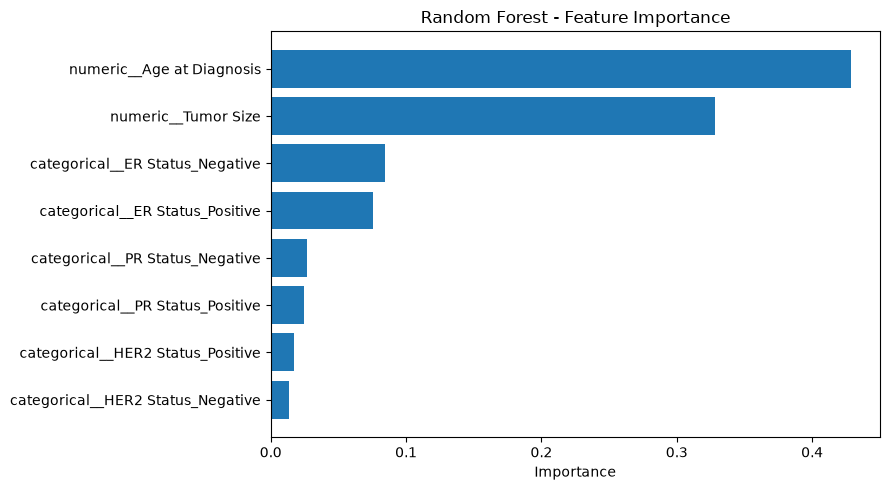

In [24]:

# 3. Feature Importance
preprocessor = final_model.named_steps["preprocessing"]
classifier = final_model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
}).sort_values("Importance", ascending=False)

print("FEATURE IMPORTANCE")
show_table(importance.round(4))

# Feature importance chart
plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 8. Leakage precautions and limitations

- The feature list is deliberately restricted to age, tumor size, and ER/PR/HER2 status. It excludes Nottingham prognostic index (which contains grade-related information), IDs, survival and relapse outcomes, and other outcome-derived fields.
- Tumor size and receptor status may be measured during the same diagnostic workup as histologic grade. Their suitability depends on when the intended user needs a prediction; do not claim prospective usefulness unless those measurements are available at that time.
- The stratified split is at the row level and does not group by patient. If multiple rows from one patient are present in a future dataset version, use a patient-group split to avoid overlap.
- Grade is treated as a nominal three-class target. Accuracy and macro F1 do not represent the ordinal distance between grade errors.
- Class imbalance, missing feature values, dataset-specific measurement practices, and a single held-out split can affect reported metrics. Use cross-validation and external validation in later work.
- This is an educational research workflow, not a diagnostic system. Results are not clinically validated and must not guide care.